# Bisection check (Python)

Checks `thole.roots.bisect` against analytic roots, mpmath, SciPy, and the step count the Lean theorem predicts.
Start JupyterLab with `workshop run -- notebook`. After changing the Rust code, restart it.

In [1]:
import math, sys
import mpmath
from scipy import optimize
import matplotlib.pyplot as plt
from thole.roots import bisect, ConvergenceError, Root

XTOL, RTOL = 2e-12, 4 * sys.float_info.epsilon   # the defaults

## 1. A first call

In [2]:
r = bisect(lambda x: x * x - 2, 0, 2)
print(r.x, r.lo, r.hi, r.iterations)
print("error      :", abs(r.x - math.sqrt(2)))
print("allowed    :", XTOL + RTOL * abs(r.x))
print("hex (compare with the Rust notebook):", r.x.hex())

1.4142135623715149 1.4142135623696959 1.4142135623733338 39
error      : 1.5802914532514478e-12
allowed    : 2.0012560739669456e-12
hex (compare with the Rust notebook): 0x1.6a09e667f2000p+0


## 2. Against mpmath (50 digits) and SciPy

SciPy's `bisect` has the same default tolerances, but a slightly different stopping rule, so the two agree within the tolerance, not bit for bit.

In [3]:
mpmath.mp.dps = 50
problems = [
    ("x^3 - x - 2",  lambda x: x**3 - x - 2,        1.0, 2.0),
    ("cos x - x",    lambda x: math.cos(x) - x,     0.0, 1.0),
    ("x e^x - 1",    lambda x: x * math.exp(x) - 1, 0.0, 1.0),
    ("x^2 - 2",      lambda x: x * x - 2,           0.0, 2.0),
    ("cos x",        math.cos,                      0.0, 2.0),
]
mp_f = {
    "x^3 - x - 2": lambda x: x**3 - x - 2,
    "cos x - x":   lambda x: mpmath.cos(x) - x,
    "x e^x - 1":   lambda x: x * mpmath.exp(x) - 1,
    "x^2 - 2":     lambda x: x * x - 2,
    "cos x":       mpmath.cos,
}
print(f"{'f':14}{'thole':>22}{'|thole - exact|':>18}{'|scipy - exact|':>18}{'steps':>7}  ok")
for name, f, a, b in problems:
    exact = mpmath.findroot(mp_f[name], (a + b) / 2)
    r = bisect(f, a, b)
    s = optimize.bisect(f, a, b)
    err = abs(mpmath.mpf(r.x) - exact)
    ok = err <= XTOL + RTOL * abs(r.x)
    print(f"{name:14}{r.x:22.16f}{float(err):18.3e}{float(abs(mpmath.mpf(s) - exact)):18.3e}{r.iterations:7d}  {ok}")

f                              thole   |thole - exact|   |scipy - exact|  steps  ok
x^3 - x - 2       1.5213797068045096         5.795e-14         5.795e-14     38  True
cos x - x         0.7390851332147577         4.030e-13         4.030e-13     38  True
x e^x - 1         0.5671432904109679         1.184e-12         1.184e-12     38  True
x^2 - 2           1.4142135623715149         1.580e-12         1.580e-12     39  True
cos x             1.5707963267941523         7.444e-13         7.444e-13     39  True


## 3. The step count predicted by the Lean proof

`bisectMid_error`: after `n` steps the error is at most `(b - a) / 2^(n + 1)`. With `rtol = 0` the loop must stop at the smallest `n` with `(b - a) / 2^(n + 1) <= xtol`.

In [4]:
def predicted_steps(a, b, xtol):
    n = 0
    while (b - a) / 2 ** (n + 1) > xtol:
        n += 1
    return n

for a, b, xtol in [(0.0, 1.0, 1e-3), (0.0, 1.0, 1e-6), (-3.0, 5.0, 1e-9), (1.0, 2.0, 0.25), (0.0, 1.0, 0.5)]:
    r = bisect(lambda x: x - (a + 0.3 * (b - a)), a, b, xtol=xtol, rtol=0.0)
    n = predicted_steps(a, b, xtol)
    print(f"[{a}, {b}] xtol={xtol:<7g} steps={r.iterations:3d} predicted={n:3d} "
          f"half width={(r.hi - r.lo) / 2:.3e}  {'ok' if r.iterations == n else 'MISMATCH'}")

[0.0, 1.0] xtol=0.001   steps=  9 predicted=  9 half width=9.766e-04  ok
[0.0, 1.0] xtol=1e-06   steps= 19 predicted= 19 half width=9.537e-07  ok
[-3.0, 5.0] xtol=1e-09   steps= 32 predicted= 32 half width=9.313e-10  ok
[1.0, 2.0] xtol=0.25    steps=  1 predicted=  1 half width=2.500e-01  ok
[0.0, 1.0] xtol=0.5     steps=  0 predicted=  0 half width=5.000e-01  ok


## 4. The bracket halves every step

Record every point where `f` is evaluated. The first two are `a` and `b`; the rest are the midpoints.

evaluations: 41 = 2 + 39


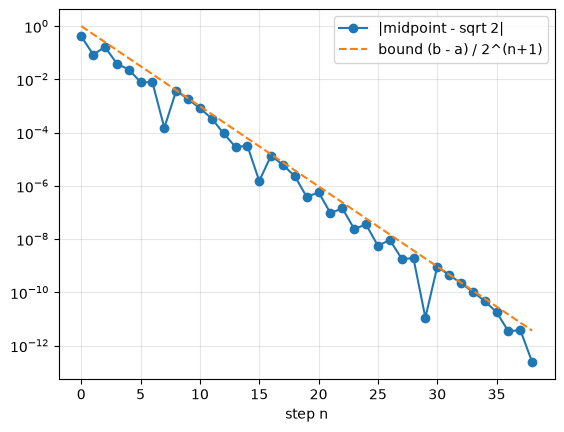

In [5]:
root = math.sqrt(2)
seen = []
def f(x):
    seen.append(x)
    return x * x - 2

r = bisect(f, 0, 2)
mids = seen[2:]
print("evaluations:", len(seen), "= 2 +", r.iterations)

n = range(len(mids))
plt.semilogy(n, [abs(m - root) for m in mids], "o-", label="|midpoint - sqrt 2|")
plt.semilogy(n, [2 / 2 ** (k + 1) for k in n], "--", label="bound (b - a) / 2^(n+1)")
plt.xlabel("step n"); plt.legend(); plt.grid(True, which="both", alpha=0.3); plt.show()

assert all(abs(m - root) <= 2 / 2 ** (k + 1) for k, m in enumerate(mids))

## 5. Failures

In [6]:
cases = {
    "no sign change":          lambda: bisect(lambda x: x * x + 1, 0, 2),
    "a > b":                   lambda: bisect(lambda x: x, 1, -1),
    "infinite endpoint":       lambda: bisect(lambda x: x, -math.inf, 1),
    "negative tolerance":      lambda: bisect(lambda x: x, -1, 1, xtol=-1.0),
    "f returns NaN":           lambda: bisect(lambda x: math.nan, 0, 1),
    "max_iter too small":      lambda: bisect(math.cos, 0, 2, max_iter=3),
    "tolerance below spacing": lambda: bisect(lambda x: x - 1e10 / 3, 0, 1e10, xtol=0.0, rtol=0.0),
    "f raises":                lambda: bisect(lambda x: 1 / 0, 0, 1),
}
for name, call in cases.items():
    try:
        print(f"{name:26} -> returned {call()!r}")
    except Exception as e:
        print(f"{name:26} -> {type(e).__name__}: {e}")

no sign change             -> ValueError: no sign change over the bracket: f(a) = 1, f(b) = 5
a > b                      -> ValueError: invalid bracket [1, -1]: need finite a <= b
infinite endpoint          -> ValueError: invalid bracket [-inf, 1]: need finite a <= b
negative tolerance         -> ValueError: invalid tolerance (abs = -1, rel = 0.0000000000000008881784197001252): both must be non-negative
f returns NaN              -> ValueError: the function returned NaN at x = 0
max_iter too small         -> ConvergenceError: tolerance not reached after 3 iterations; last bracket [1.5, 1.75]
tolerance below spacing    -> ConvergenceError: tolerance not reached after 100 iterations; last bracket [3333333333.333333, 3333333333.3333335]
f raises                   -> ZeroDivisionError: division by zero


## 6. Edge cases

A root at an endpoint, and a discontinuous function: bisection cannot tell a pole from a root, as the documentation says.

In [7]:
for name, f, a, b in [
    ("root at a",        lambda x: x,       0.0, 1.0),
    ("root at b",        lambda x: x - 1,   0.0, 1.0),
    ("a == b on a root", lambda x: x - 1,   1.0, 1.0),
    ("pole of 1/x",      lambda x: 1 / x,  -1.0, 2.0),
    ("three roots",      lambda x: x**3 - x, -2.0, 3.0),
]:
    try:
        r = bisect(f, a, b)
        print(f"{name:18} x={r.x:.15g}  [{r.lo:.15g}, {r.hi:.15g}]  steps={r.iterations}")
    except Exception as e:
        print(f"{name:18} {type(e).__name__}: {e}")

root at a          x=1.81898940354586e-12  [0, 3.63797880709171e-12]  steps=38
root at b          x=0.999999999998181  [0.999999999996362, 1]  steps=38
a == b on a root   x=1  [1, 1]  steps=0
pole of 1/x        x=4.54747350886464e-13  [-9.09494701772928e-13, 1.81898940354586e-12]  steps=40
three roots        x=1.00000000000068  [0.999999999999545, 1.00000000000182]  steps=41


## 7. Try your own

In [8]:
r = bisect(lambda x: math.sin(x) - 0.5, 0, 1)
r.x, math.pi / 6, r.iterations

(0.5235987755968381, 0.5235987755982988, 38)